# Drug similarity through a computer's eyes

**Question:** Do drugs from the same class also look similar to a computer?

Eight drugs were chosen in pairs: two xanthines (caffeine, theophylline), two
opioids (morphine, codeine), two propionic-acid NSAIDs (ibuprofen, naproxen)
and two common painkillers with different structures (aspirin, paracetamol).
Each molecule is turned into a Morgan fingerprint, and every pair is compared
with the Tanimoto similarity (0 = nothing in common, 1 = identical).

In [1]:
from rdkit import Chem, DataStructs
from rdkit.Chem import Draw, rdFingerprintGenerator
import matplotlib.pyplot as plt

## 1. The drugs

In [2]:
DRUGS = {
    
    "caffeine": "CN1C=NC2=C1C(=O)N(C)C(=O)N2C",
    "theophylline": "CN1C2=C(C(=O)N(C1=O)C)NC=N2",
    "morphine": "CN1CC[C@]23[C@@H]4[C@H]1CC5=C2C(=C(C=C5)O)O[C@H]3[C@H](C=C4)O",
    "codeine": "CN1CC[C@]23[C@@H]4[C@H]1CC5=C2C(=C(C=C5)OC)O[C@H]3[C@H](C=C4)O",
    "ibuprofen" : "CC(C)Cc1ccc(cc1)C(C)C(=O)O",
    "naproxen" : "C[C@H](C(=O)O)c1ccc2cc(OC)ccc2c1",
    "aspirin": "CC(=O)Oc1ccccc1C(=O)O", 
    "paracetamol": "CC(=O)Nc1ccc(O)cc1"
   
}

print(len(DRUGS), "drugs")

8 drugs


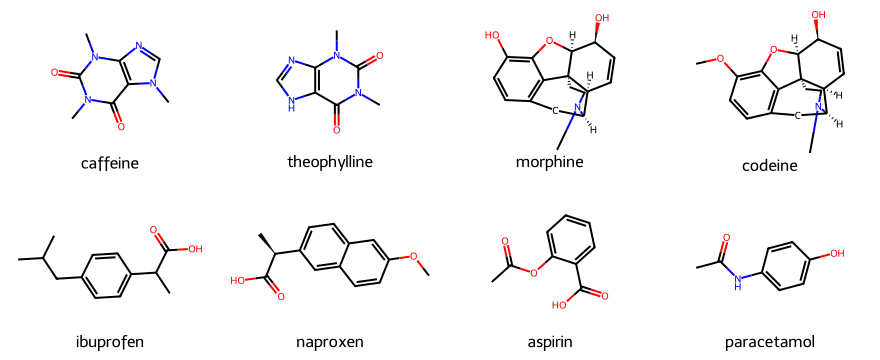

In [3]:
names = list(DRUGS)
mols = [Chem.MolFromSmiles(DRUGS[name]) for name in names]
Draw.MolsToGridImage(mols, legends=names, molsPerRow=4, subImgSize=(220, 180))

## 2. Fingerprints

A Morgan fingerprint (radius 2, 2048 bits) records which small circular
neighbourhoods of atoms occur in a molecule. Two molecules that share many of
these neighbourhoods have a high Tanimoto similarity.

In [4]:
generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)


def fingerprint(smiles):
    """Return the Morgan fingerprint of a SMILES string."""

    mol = Chem.MolFromSmiles(smiles)
    fp = generator.GetFingerprint(mol)
    return fp

def similarity(smiles_a, smiles_b):
    """Return the Tanimoto similarity of two molecules."""
   
    fp_a = fingerprint(smiles_a)
    fp_b = fingerprint(smiles_b)
    score = DataStructs.TanimotoSimilarity(fp_a, fp_b)
    return score

**Check:** a molecule compared with itself must give exactly 1.0, and two
different molecules must give less than 1.0. If this cell fails, fix the
functions above before going on.

In [5]:
assert similarity(DRUGS["caffeine"], DRUGS["caffeine"]) == 1.0
assert similarity(DRUGS["caffeine"], DRUGS["morphine"]) < 1.0
print("checks passed")

checks passed


## 3. All pairs

In [6]:
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        a = names[i]
        b = names[j]
        score = similarity(DRUGS[a], DRUGS[b])
        print(f"{a} - {b}: {score:.2f}")

caffeine - theophylline: 0.46
caffeine - morphine: 0.08
caffeine - codeine: 0.07
caffeine - ibuprofen: 0.09
caffeine - naproxen: 0.08
caffeine - aspirin: 0.09
caffeine - paracetamol: 0.10
theophylline - morphine: 0.09
theophylline - codeine: 0.09
theophylline - ibuprofen: 0.09
theophylline - naproxen: 0.08
theophylline - aspirin: 0.09
theophylline - paracetamol: 0.10
morphine - codeine: 0.76
morphine - ibuprofen: 0.09
morphine - naproxen: 0.09
morphine - aspirin: 0.08
morphine - paracetamol: 0.10
codeine - ibuprofen: 0.09
codeine - naproxen: 0.13
codeine - aspirin: 0.11
codeine - paracetamol: 0.08
ibuprofen - naproxen: 0.42
ibuprofen - aspirin: 0.20
ibuprofen - paracetamol: 0.18
naproxen - aspirin: 0.20
naproxen - paracetamol: 0.17
aspirin - paracetamol: 0.22


In [7]:
best_score = 0
best_pair = None
worst_score = 1
worst_pair = None

for i in range(len(names)):
    for j in range(i + 1, len(names)):
        a = names[i]
        b = names[j]
        score = similarity(DRUGS[a], DRUGS[b])
        if score > best_score:
            best_score = score
            best_pair = (a, b)
        if score < worst_score:
            worst_score = score
            worst_pair = (a, b)

print(f"Most similar:  {best_pair[0]} - {best_pair[1]} ({best_score:.2f})")
print(f"Least similar: {worst_pair[0]} - {worst_pair[1]} ({worst_score:.2f})")

Most similar:  morphine - codeine (0.76)
Least similar: caffeine - codeine (0.07)


## 4. Similarity map

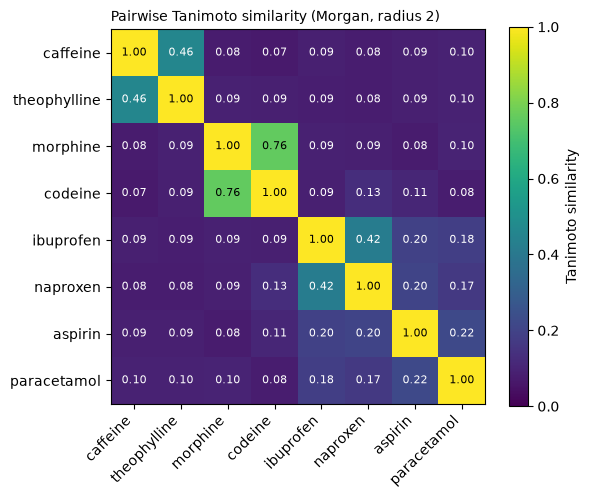

In [8]:
matrix = [[similarity(DRUGS[a], DRUGS[b]) for b in names] for a in names]

fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(matrix, cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(len(names)), names, rotation=45, ha="right")
ax.set_yticks(range(len(names)), names)
for i in range(len(names)):
    for j in range(len(names)):
        color = "black" if matrix[i][j] > 0.6 else "white"
        ax.text(j, i, f"{matrix[i][j]:.2f}", ha="center", va="center", fontsize=8, color=color)
fig.colorbar(image, ax=ax, label="Tanimoto similarity")
ax.set_title("Pairwise Tanimoto similarity (Morgan, radius 2)", loc="left", fontsize=10)
fig.tight_layout()
fig.savefig("similarity_heatmap.png", dpi=200)
plt.show()

## 5. Results

The three structural pairs came out on top: morphine and codeine (0.76),
caffeine and theophylline (0.46) and ibuprofen and naproxen (0.42).
All other pairs scored between 0.07 and 0.22.

Two results surprised me. Caffeine and theophylline differ by only one
methyl group, yet their similarity is only 0.46: in a small molecule a single
change affects a large share of the fingerprint. Aspirin and paracetamol are
both painkillers, but their similarity is only 0.22, so the same use does not
mean the same structure. Aspirin is barely more similar to paracetamol (0.22) than to ibuprofen
and naproxen (0.20 each): the fingerprint compares structure, not use.